# **Homework 5**
Name: Maddox Guthrie \
Id: 12184185

# 1.1 Exercise 1: Solving Linear System of Equations

In [6]:
import numpy as np

In [4]:
def random_upper_matrix(n, low=-3, high=3):
    a = np.random.randint(low, high, size=(n, n))
    a = np.triu(a)
    for i in range(n):
        if a[i, i] == 0:
            a[i, i] = np.random.randint(1, high)
    return a

a) Suppose $A$ is a lower matrix. Write a function to solve the system $Ax = b$ using forward substitution

In [4]:
def forward_substitution(l, b):
    n = len(b)
    x = np.empty(shape=n, dtype=float)

    for i in range(n):
        x[i] = (b[i] - np.dot(x[:i], l[i, :i])) / l[i, i]
    return x

Now test your function to make sure it works properly.

In [5]:
L = np.flip(random_upper_matrix(5))
b = np.random.randint(1, 5, size=5)

x = forward_substitution(L, b)
x_np = np.linalg.solve(L, b)

np.allclose(x, x_np)

True

b) Suppose $A$ is an upper matrix. Write a function to solve the system $Ax = b$ using backward substitution

In [6]:
def backward_substitution(u, y):
    n = len(y)
    x = np.empty(shape=n, dtype=float)

    for i in range(n - 1, -1, -1):
        x[i] = (y[i] - np.dot(x[i+1:], u[i, i+1:])) / u[i, i]
    return x

Now test your function to make sure it works properly.

In [7]:
L = random_upper_matrix(5)
b = np.random.randint(1, 5, size=5)

x = backward_substitution(L, b)
x_np = np.linalg.solve(L, b)

np.allclose(x, x_np)

True

# 1.2 Exercise 2: LU Decomposition
Write a Python function that takes the input as an $n \times n$ matrix and return the lower and upper matrices in the LU decomposition form. Students need to implement the algorithm from the scratch as we did in class.

In [20]:
def lu_decomposition(a):

    pass

Test your function by using `random_upper_matrix` above.

In [21]:
a = random_upper_matrix(5)
b = random_upper_matrix(5)
c = a.T @ b
l, u = lu_decomposition(c)

TypeError: cannot unpack non-iterable NoneType object

In [22]:
# check if the decomposition is correct
assert np.allclose(l @ u, c), "LU decomposition is incorrect"

AssertionError: LU decomposition is incorrect

# 1.3 Exercise 3: Computational Complexity of LU Decomposition
Conduct an experiment to analyze the computational complexity of LU decomposition by visualizing the relationship between matrix size and execution time using a log-log plot.

- **Generate Random Matrices:** Create square matrices $A$ with sizes ranging from $n = 1000$ to $n = 5000$ in increments of 100.
- **Measure Execution Time:** Use `scipy.linalg.lu()` function from Scipy to compute the LU decomposition for each matrix, recording the execution time.
- **Collect Data:** Store each matrix size $n$ and its corresponding computation time for analysis.
- **Log-Log Plot:** Plot the graph to visualize the scaling behavior of execution time with respect to matrix size.
- **Analyze Complexity:** Determine the slope of the log-log plot to assess the computational complexity of LU decomposition. Compare the observed trend with the expected $𝑂(n^3)$ complexity and discuss any deviations or insights from the experiment.

In [8]:
import matplotlib.pyplot as plt
import time
import numpy as np
import scipy

In [13]:
start_size = 1000
end_size = 5000
step_size = 100

In [14]:
sizes = range(start_size, end_size + 1, step_size)
times = []

In [15]:
scipy.linalg.lu(np.random.rand(1000, 1000)) # Pre-initialize BLAS
for n in sizes:
    A = np.random.randint(1, 10, size=(n, n))

    start = time.time()
    scipy.linalg.lu(A)
    end = time.time()

    times.append(end - start)

In [16]:
sizes = np.arange(start_size, end_size + 1, step_size)

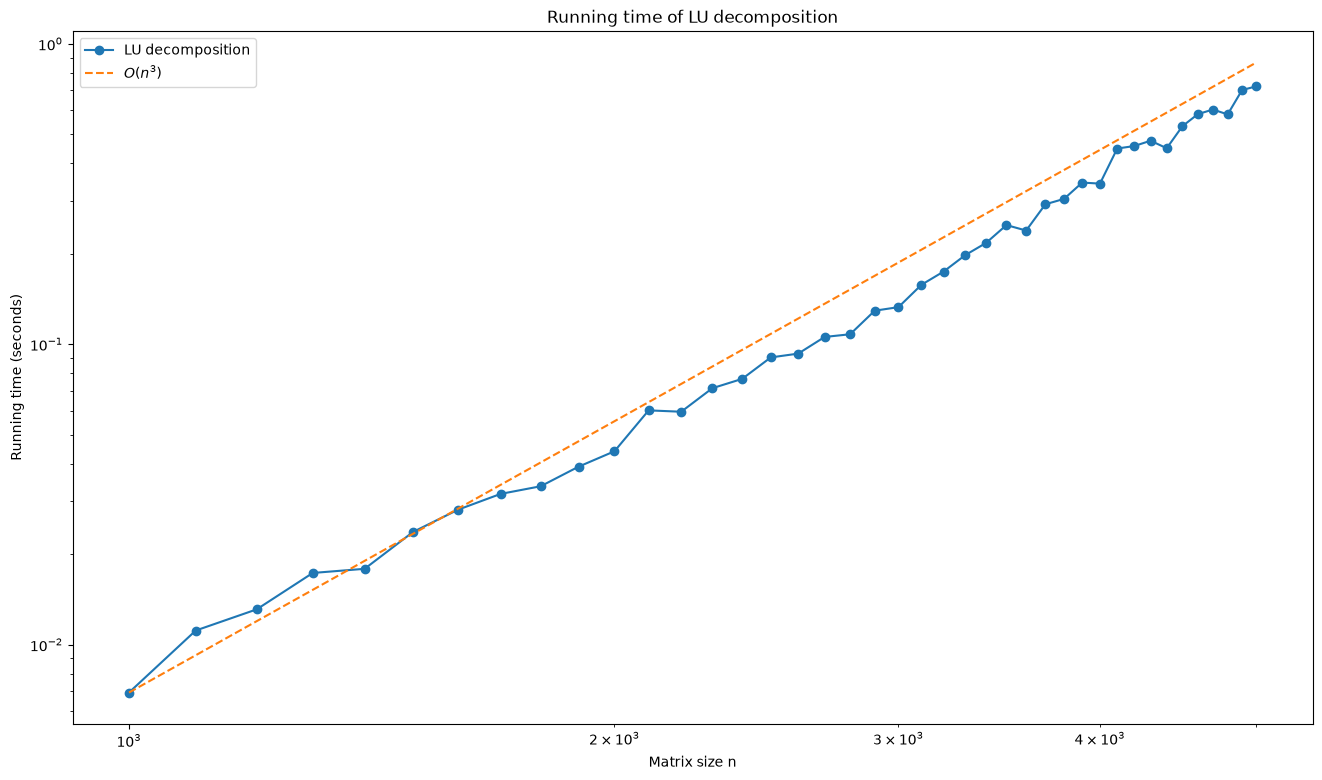

In [17]:
fig, ax = plt.subplots(figsize=(16, 9))

ax.loglog(sizes, times, "o-", label="LU decomposition")
ax.loglog(sizes, times[0] * (sizes / sizes[0])**3, "--", label=r"$O(n^3)$")

ax.set_title("Running time of LU decomposition")
ax.set_xlabel("Matrix size n")
ax.set_ylabel("Running time (seconds)")
ax.legend()

plt.show()

In [18]:
slope, intercept = np.polyfit(np.log(sizes), np.log(times), 1)
print(f"slope = {slope:.2f}")

slope = 2.83


In [19]:
slope, intercept = np.polyfit(np.log(sizes), np.log(times[0] * (sizes / sizes[0])**3), 1)
print(f"slope = {slope:.2f}")

slope = 3.00


The log-log plot of running time vs. matrix size is close to a straight line. The slope of the fitted line is about $2.67$, which is close to the expected $3$ for LU decomposition, since it takes about $(\frac{2}{3})n^3$ operations. The line is a little below the $O(n^3)$ reference line, and there is some noise in the points. This is probably because at smaller $n$, memory access and other overheads matter more than the actual computation, and SciPy’s multithreaded BLAS is more efficient for larger matrices. Other programs running on the computer could also add noise to the timings. The first data point was also an outlier from start-up overhead, so I ran the function once before timing the results. Overall the experiment supports $O(n^3)$ complexity.